<a href="https://colab.research.google.com/github/KzDwi/KBPA/blob/main/AIPA_2_Almost.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Klasifikasi Spesies Ikan dengan Custom CNN (From Scratch)

**Dataset:** Fish Dataset (Kaggle), `markdaniellampa/fish-dataset`, 31 spesies ikan air tawar
**Metode:** Supervised learning, klasifikasi multi-kelas
**Model:** Custom CNN residual + Squeeze-Excitation, dilatih dari nol (tanpa transfer learning)
**Deployment:** Streamlit

**Alur:** Setup → Dataset → EDA → Preprocessing → Model → Training → Evaluasi → Simpan model → Streamlit → (opsional) Eksplorasi hyperparameter

## 1. Setup

Import library, set random seed, cek GPU, dan mount Google Drive untuk backup model.

In [ ]:
!pip install -q kagglehub

import io
import os
import json
import shutil
import random
import hashlib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from collections import Counter
from PIL import Image, ImageOps

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks
from tensorflow.keras.utils import plot_model

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import classification_report, confusion_matrix, f1_score

import kagglehub
from google.colab import drive

warnings.filterwarnings('ignore')

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("=" * 60)
print("VERSI LIBRARY")
print("=" * 60)
print(f"TensorFlow  : {tf.__version__}")
print(f"NumPy       : {np.__version__}")
print(f"Pandas      : {pd.__version__}")
print(f"Scikit-learn: {sklearn.__version__}")

print("\n" + "=" * 60)
print("KONFIGURASI GPU")
print("=" * 60)
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"GPU terdeteksi: {len(gpus)}")
    for gpu in gpus:
        print(f"  - {gpu.name}")
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except RuntimeError as e:
            print(f"    (memory growth tidak dapat diatur: {e})")
else:
    print("Tidak ada GPU terdeteksi. Training akan berjalan di CPU (lebih lambat).")

print("\n✅ Setup selesai.")

drive.mount('/content/drive')
SAVE_DIR = '/content/drive/MyDrive/PA_KB_Ikan'
os.makedirs(SAVE_DIR, exist_ok=True)

VERSI LIBRARY
TensorFlow  : 2.21.0
NumPy       : 2.4.6
Pandas      : 2.2.3
Scikit-learn: 1.6.1

KONFIGURASI GPU
GPU terdeteksi: 1
  - /physical_device:GPU:0

✅ Setup selesai.
Mounted at /content/drive


## 2. Download & Load Dataset

Dataset diunduh dengan `kagglehub`. Dataset bawaan sudah terbagi menjadi `train/val/test`, tetapi akan digabung dan dibagi ulang di Section 4 (alasannya dijelaskan di sana).

In [ ]:
DATASET_HANDLE = "markdaniellampa/fish-dataset"

print("Mengunduh dataset...")
dataset_path = kagglehub.dataset_download(DATASET_HANDLE)
print(f"\n✅ Dataset tersedia di: {dataset_path}")

print("\n" + "=" * 60)
print("STRUKTUR DIREKTORI DATASET (3 level teratas)")
print("=" * 60)

for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, '').count(os.sep)
    if level >= 3:
        continue
    indent = '  ' * level
    print(f"{indent}{os.path.basename(root)}/")
    if level < 2:
        for f in files[:3]:
            print(f"{indent}  {f}")
        if len(files) > 3:
            print(f"{indent}  ... ({len(files)} file total)")

Mengunduh dataset...


100%|██████████| 1.58G/1.58G [01:31<00:00, 18.5MB/s]

Extracting files...



✅ Dataset tersedia di: /root/.cache/kagglehub/datasets/markdaniellampa/fish-dataset/versions/1

STRUKTUR DIREKTORI DATASET (3 level teratas)
1/
  FishImgDataset/
    test/
    train/
    val/


In [ ]:
ROOT = os.path.join(dataset_path, "FishImgDataset")
EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.gif'}

def count_split(split):
    d = os.path.join(ROOT, split)
    counts = {}
    for c in sorted(os.listdir(d)):
        cd = os.path.join(d, c)
        if os.path.isdir(cd):
            n = len([f for f in os.listdir(cd)
                     if os.path.splitext(f)[1].lower() in EXTS])
            if n > 0:
                counts[c] = n
    return counts

split_counts = {s: count_split(s) for s in ["train", "val", "test"]}

print("=" * 60)
print("JUMLAH DATA PER SPLIT")
print("=" * 60)
for s, cnt in split_counts.items():
    print(f"{s:<6}: {len(cnt)} kelas, {sum(cnt.values()):>6,} gambar")

assert set(split_counts["train"]) == set(split_counts["val"]) == set(split_counts["test"]), \
    "Nama kelas tidak sama antar split!"

# dipakai oleh sel EDA di bawah
CLASS_ROOT = os.path.join(ROOT, "train")
class_counts = split_counts["train"]

print("\nJUMLAH KELAS:", len(class_counts))
for cls, count in sorted(class_counts.items(), key=lambda x: -x[1]):
    print(f"  {cls:<30}: {count:>5} gambar (train)")

JUMLAH DATA PER SPLIT
train : 31 kelas,  8,808 gambar
val   : 31 kelas,  2,751 gambar
test  : 31 kelas,  1,761 gambar

JUMLAH KELAS: 31
  Grass Carp                    :  1212 gambar (train)
  Goby                          :   607 gambar (train)
  Glass Perchlet                :   399 gambar (train)
  Silver Barb                   :   329 gambar (train)
  Knifefish                     :   318 gambar (train)
  Catfish                       :   314 gambar (train)
  Gourami                       :   312 gambar (train)
  Tilapia                       :   302 gambar (train)
  Perch                         :   293 gambar (train)
  Janitor Fish                  :   286 gambar (train)
  Silver Perch                  :   283 gambar (train)
  Tenpounder                    :   277 gambar (train)
  Freshwater Eel                :   273 gambar (train)
  Indian Carp                   :   262 gambar (train)
  Long-Snouted Pipefish         :   256 gambar (train)
  Mosquito Fish                 :   256

## 3. Exploratory Data Analysis (EDA)

EDA dijalankan pada data mentah (sebelum deduplikasi). Dua temuan yang memengaruhi desain:
- **Ukuran gambar sangat bervariasi** (77–5184 px), sehingga semua gambar di-resize ke ukuran seragam.
- **Kelas tidak seimbang** (rasio mayoritas/minoritas ±11x), sehingga dipakai bobot kelas.

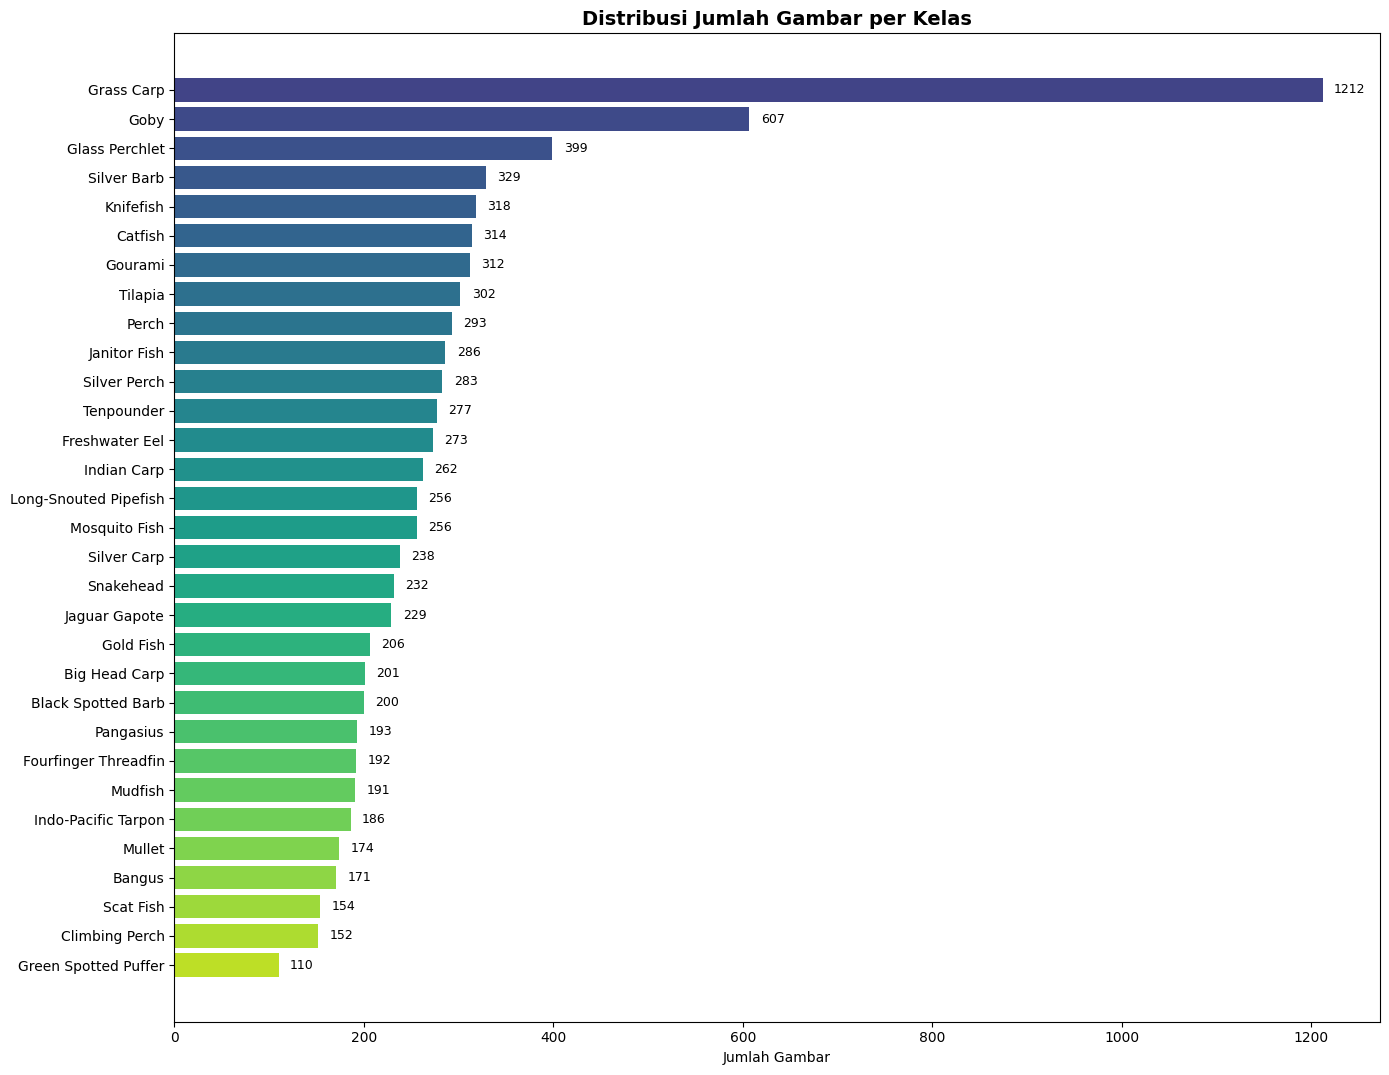


Rasio kelas mayoritas/minoritas: 11.02
⚠️  Dataset tidak seimbang (imbalanced). Pertimbangkan class weights.


In [ ]:
fig, ax = plt.subplots(figsize=(14, max(6, len(class_counts) * 0.35)))
classes_sorted = sorted(class_counts.items(), key=lambda x: x[1], reverse=True)
names = [c[0] for c in classes_sorted]
values = [c[1] for c in classes_sorted]

bars = ax.barh(names, values, color=plt.cm.viridis(np.linspace(0.2, 0.9, len(names))))
ax.set_xlabel('Jumlah Gambar')
ax.set_title('Distribusi Jumlah Gambar per Kelas', fontsize=14, fontweight='bold')
ax.invert_yaxis()
for bar, val in zip(bars, values):
    ax.text(val + max(values)*0.01, bar.get_y() + bar.get_height()/2,
            f'{val}', va='center', fontsize=9)
plt.tight_layout()
plt.show()

min_count = min(values)
max_count = max(values)
ratio = max_count / min_count
print(f"\nRasio kelas mayoritas/minoritas: {ratio:.2f}")
if ratio > 3:
    print("⚠️  Dataset tidak seimbang (imbalanced). Pertimbangkan class weights.")
else:
    print("✅ Dataset relatif seimbang.")

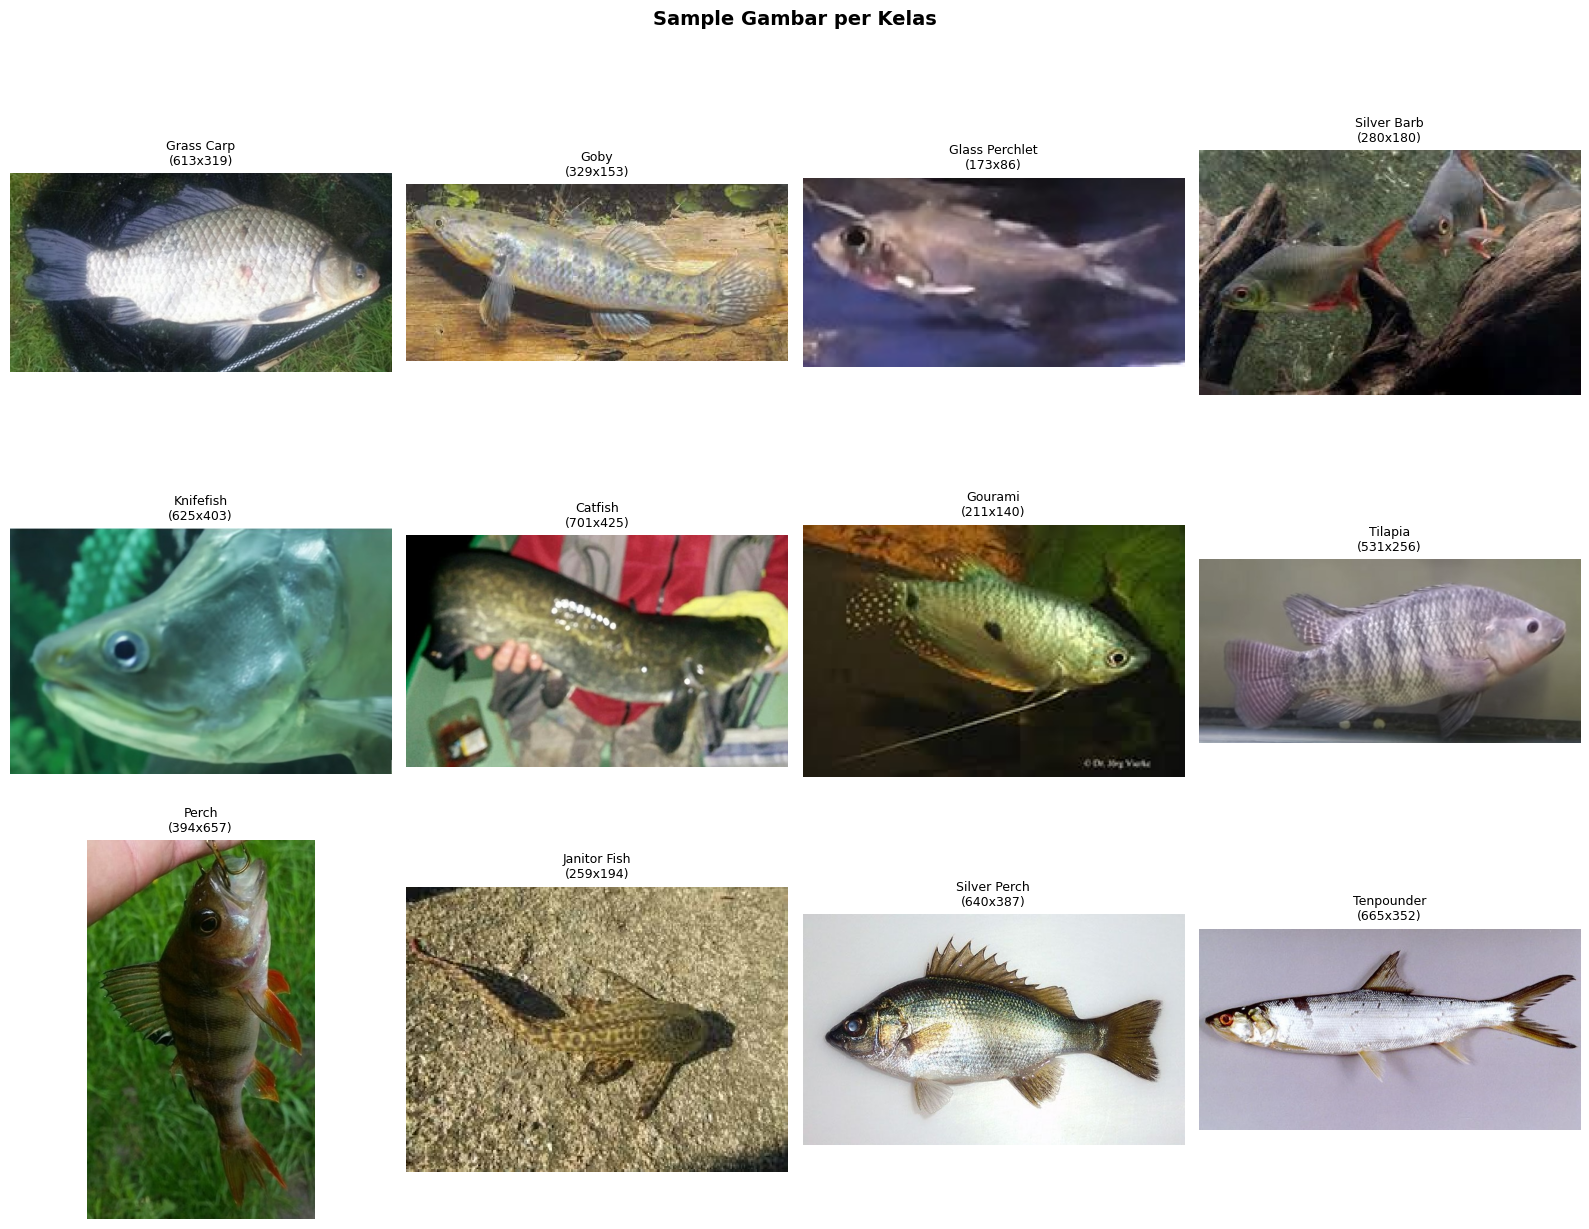

In [ ]:
def show_sample_images(class_root, class_names, n_per_class=1, max_classes=12):
    """Menampilkan grid sample gambar dari beberapa kelas."""
    classes_to_show = class_names[:max_classes]
    n_cols = min(4, len(classes_to_show))
    n_rows = (len(classes_to_show) + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows))
    axes = axes.flatten() if n_rows * n_cols > 1 else [axes]

    for idx, cls in enumerate(classes_to_show):
        class_dir = os.path.join(class_root, cls)
        img_files = [f for f in os.listdir(class_dir)
                     if os.path.splitext(f)[1].lower() in {'.jpg', '.jpeg', '.png', '.bmp', '.gif'}]
        if not img_files:
            continue
        img_path = os.path.join(class_dir, img_files[0])
        img = Image.open(img_path).convert('RGB')

        axes[idx].imshow(img)
        axes[idx].set_title(f"{cls}\n({img.size[0]}x{img.size[1]})", fontsize=9)
        axes[idx].axis('off')

    for j in range(len(classes_to_show), len(axes)):
        axes[j].axis('off')

    plt.suptitle('Sample Gambar per Kelas', fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

show_sample_images(CLASS_ROOT, names, max_classes=12)

STATISTIK DIMENSI GAMBAR (sampel)
Jumlah sampel valid : 500
Width  — min:   41, max: 5184, mean: 610.5
Height — min:   61, max: 3456, mean: 408.2
Channel — distribusi: Counter({3: 497, 4: 3})


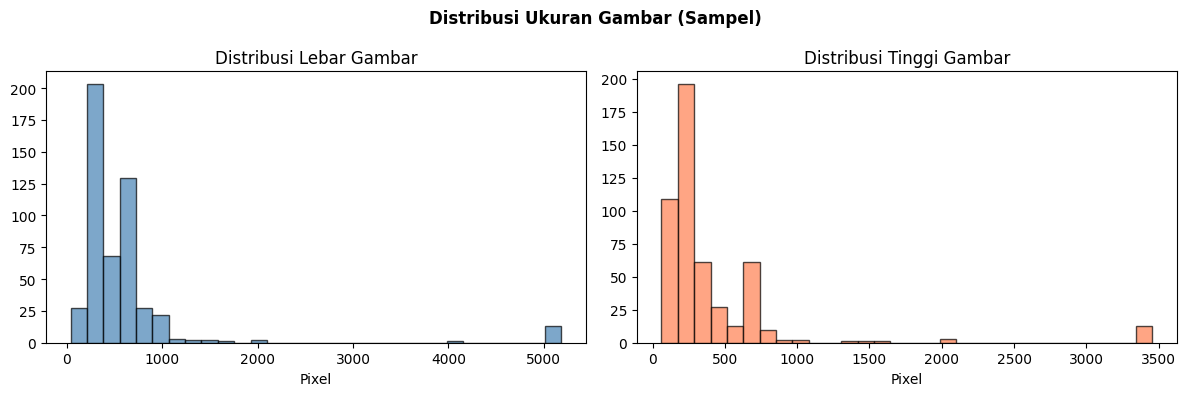

In [ ]:
all_image_paths = []
for cls, _ in class_counts.items():
    class_dir = os.path.join(CLASS_ROOT, cls)
    files = [os.path.join(class_dir, f) for f in os.listdir(class_dir)
             if os.path.splitext(f)[1].lower() in {'.jpg', '.jpeg', '.png', '.bmp', '.gif'}]
    all_image_paths.extend(files)

random.shuffle(all_image_paths)
sample_paths = all_image_paths[:500]

widths, heights, channels = [], [], []
for p in sample_paths:
    try:
        with Image.open(p) as img:
            w, h = img.size
            c = len(img.getbands()) if img.mode != 'P' else 3
            widths.append(w)
            heights.append(h)
            channels.append(c)
    except Exception:
        continue

print("=" * 60)
print("STATISTIK DIMENSI GAMBAR (sampel)")
print("=" * 60)
print(f"Jumlah sampel valid : {len(widths)}")
print(f"Width  — min: {min(widths):>4}, max: {max(widths):>4}, mean: {np.mean(widths):.1f}")
print(f"Height — min: {min(heights):>4}, max: {max(heights):>4}, mean: {np.mean(heights):.1f}")
print(f"Channel — distribusi: {Counter(channels)}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(widths, bins=30, color='steelblue', edgecolor='black', alpha=0.7)
axes[0].set_title('Distribusi Lebar Gambar')
axes[0].set_xlabel('Pixel')

axes[1].hist(heights, bins=30, color='coral', edgecolor='black', alpha=0.7)
axes[1].set_title('Distribusi Tinggi Gambar')
axes[1].set_xlabel('Pixel')

plt.suptitle('Distribusi Ukuran Gambar (Sampel)', fontweight='bold')
plt.tight_layout()
plt.show()

## 4. Preprocessing & Augmentation

Dataset Kaggle mengandung banyak duplikat antar split (4.404 dari 13.320 gambar identik). Jika dibiarkan, gambar yang sama muncul di train dan test sehingga akurasi tampak lebih tinggi dari sebenarnya. Langkah yang dilakukan:

1. Gabungkan 3 split bawaan, lalu buang duplikat persis (md5), gambar rusak, dan gambar terlalu kecil.
2. Kelompokkan near-duplicate (dHash, termasuk versi mirror), lalu bagi ulang 70/15/15 secara **stratified + group** agar satu grup tidak terpisah antar split.
3. Resize 224×224 dengan padding (rasio aspek ikan terjaga), normalisasi ke [0, 1].
4. Bobot kelas dilunakkan (akar dari balanced weight) untuk menangani imbalance.
5. Augmentasi hanya saat training: flip, rotasi, zoom, translasi, kontras, brightness, noise, blur, dan random erasing.
6. **MixUp + CutMix** per batch untuk menekan overfitting, karena setelah deduplikasi hanya tersisa ±200 gambar per kelas.

In [ ]:
IMG_SIZE   = (224, 224)
BATCH_SIZE = 32
AUTOTUNE   = tf.data.AUTOTUNE
USE_PAD    = True
MIN_SIDE   = 32
NEAR_DUP_THRESHOLD = 4
USE_MIXED_PRECISION = True

if USE_MIXED_PRECISION and tf.config.list_physical_devices('GPU'):
    keras.mixed_precision.set_global_policy('mixed_float16')
print("Policy:", keras.mixed_precision.global_policy().name)

class_names_ordered = sorted(class_counts.keys())
class_to_idx = {c: i for i, c in enumerate(class_names_ordered)}
idx_to_class = {i: c for c, i in class_to_idx.items()}
NUM_CLASSES  = len(class_names_ordered)

# 1. Gabungkan 3 split bawaan Kaggle
items = []
for s in ["train", "val", "test"]:
    for c in class_names_ordered:
        d = os.path.join(ROOT, s, c)
        for f in sorted(os.listdir(d)):
            if os.path.splitext(f)[1].lower() in EXTS:
                items.append((os.path.join(d, f), class_to_idx[c]))
total_awal = len(items)

# 2. Buang duplikat persis (md5) dan hitung dHash untuk near-duplicate
def dhash_bits(img_l):
    a = np.asarray(img_l.resize((9, 8), Image.BILINEAR), dtype=np.int16)
    return (a[:, 1:] > a[:, :-1]).flatten()

seen, conflict, rows = {}, set(), []
n_kecil = n_rusak = 0
for p, l in items:
    try:
        with open(p, 'rb') as fh:
            b = fh.read()
        h = hashlib.md5(b).hexdigest()
        if h in seen:
            if seen[h] != l:
                conflict.add(h)
            continue
        seen[h] = l
        img = Image.open(io.BytesIO(b))
        w, ht = img.size
        if min(w, ht) < MIN_SIDE:
            n_kecil += 1
            continue
        img.draft('L', (256, 256))
        img = img.convert('L')
        rows.append((p, l, h, dhash_bits(img), dhash_bits(ImageOps.mirror(img))))
    except Exception:
        n_rusak += 1

rows = [r for r in rows if r[2] not in conflict]
paths  = np.array([r[0] for r in rows])
labels = np.array([r[1] for r in rows])
Bits   = np.packbits(np.stack([r[3] for r in rows]), axis=1)
BitsF  = np.packbits(np.stack([r[4] for r in rows]), axis=1)

# 3. Kelompokkan near-duplicate (union-find)
POP = np.array([bin(i).count('1') for i in range(256)], dtype=np.uint8)
n = len(paths)
parent = list(range(n))
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x
for i in range(n - 1):
    d1 = POP[Bits[i+1:] ^ Bits[i]].sum(1)
    d2 = POP[BitsF[i+1:] ^ Bits[i]].sum(1)
    for j in np.nonzero(np.minimum(d1, d2) <= NEAR_DUP_THRESHOLD)[0]:
        a, b_ = find(i), find(i + 1 + j)
        if a != b_:
            parent[a] = b_
groups = np.array([find(i) for i in range(n)])
gsize = Counter(groups)

print("=" * 60)
print("DEDUPLIKASI & NEAR-DUPLICATE")
print("=" * 60)
print(f"Total gambar awal (3 split)  : {total_awal}")
print(f"Duplikat persis dibuang (md5): {total_awal - len(seen) - n_rusak}")
print(f"Terlalu kecil (<{MIN_SIDE}px)       : {n_kecil}")
print(f"Rusak / gagal dibaca         : {n_rusak}")
print(f"Gambar dipakai               : {n}")
print(f"Jumlah grup near-duplicate   : {len(gsize)}  (grup berisi >1 gambar: {sum(v>1 for v in gsize.values())})")
print(f"Ukuran grup terbesar         : {max(gsize.values())}")

# 4. Split 70/15/15 stratified + group
sgkf = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEED)
folds = [te for _, te in sgkf.split(paths, labels, groups)]
test_idx  = np.concatenate(folds[0:3])
val_idx   = np.concatenate(folds[3:6])
train_idx = np.concatenate(folds[6:])

X_train_paths, y_train = paths[train_idx], labels[train_idx]
X_val_paths,   y_val   = paths[val_idx],   labels[val_idx]
X_test_paths,  y_test  = paths[test_idx],  labels[test_idx]

g_tr, g_va, g_te = set(groups[train_idx]), set(groups[val_idx]), set(groups[test_idx])
assert not (g_tr & g_va) and not (g_tr & g_te) and not (g_va & g_te), "Ada grup yang bocor antar split!"
for nm, y in [("train", y_train), ("val", y_val), ("test", y_test)]:
    assert len(np.unique(y)) == NUM_CLASSES, f"Ada kelas yang hilang di {nm}"

print("\n" + "=" * 60)
print("PEMBAGIAN DATASET")
print("=" * 60)
print(f"Train      : {len(X_train_paths):>6} gambar")
print(f"Validation : {len(X_val_paths):>6} gambar")
print(f"Test       : {len(X_test_paths):>6} gambar")

# 5. Bobot kelas (akar dari balanced weight)
cnt = np.bincount(y_train, minlength=NUM_CLASSES).astype(np.float64)
cw = np.sqrt(
    len(y_train) / (NUM_CLASSES * cnt)
)
cw = cw / cw[y_train].mean()
CW_TABLE = tf.constant(cw, dtype=tf.float32)
print(f"Bobot kelas (soft) min/max: {cw.min():.2f} / {cw.max():.2f}")

# 6. Pipeline tf.data
def load_resize(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    if USE_PAD:
        img = tf.image.resize_with_pad(img, IMG_SIZE[0], IMG_SIZE[1])
    else:
        img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(tf.round(img), tf.uint8)
    return img, label

def to_float(img, label):
    return tf.cast(img, tf.float32) / 255.0, label

def add_weight(img, label):
    return img, label, tf.gather(CW_TABLE, label)

def create_dataset(paths_, labels_, training=False, batch_size=BATCH_SIZE):
    ds = tf.data.Dataset.from_tensor_slices((paths_, labels_.astype(np.int32)))
    ds = ds.map(load_resize, num_parallel_calls=AUTOTUNE).cache()
    if training:
        ds = ds.shuffle(len(paths_), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(to_float, num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.map(add_weight, num_parallel_calls=AUTOTUNE)
    return ds.batch(batch_size).prefetch(AUTOTUNE)

train_ds = create_dataset(X_train_paths, y_train, training=True)
val_ds   = create_dataset(X_val_paths,   y_val)
test_ds  = create_dataset(X_test_paths,  y_test)

# 7. MixUp / CutMix per batch (hanya train)
MIX_PROB     = 0.2
MIXUP_ALPHA  = 0.3
CUTMIX_ALPHA = 1.0

def _sample_beta(alpha):
    g1 = tf.random.gamma([], alpha)
    g2 = tf.random.gamma([], alpha)
    return g1 / (g1 + g2 + 1e-8)

def mix_batch(x, y, w):
    """x: (B,H,W,3) float [0,1]; y: (B,) int; w: (B,) bobot sampel.
    Keluaran: (x_mix, y_soft (B, NUM_CLASSES), w_mix). Satu batch memakai tepat satu mode."""
    B = tf.shape(x)[0]; H = tf.shape(x)[1]; W = tf.shape(x)[2]
    y_oh = tf.one_hot(y, NUM_CLASSES, dtype=tf.float32)
    perm = tf.random.shuffle(tf.range(B))
    x_p, y_p, w_p = tf.gather(x, perm), tf.gather(y_oh, perm), tf.gather(w, perm)

    def no_mix():
        return x, y_oh, w

    def mixup():
        lam = _sample_beta(MIXUP_ALPHA)
        return (lam * x + (1.0 - lam) * x_p,
                lam * y_oh + (1.0 - lam) * y_p,
                lam * w + (1.0 - lam) * w_p)

    def cutmix():
        r = tf.sqrt(1.0 - _sample_beta(CUTMIX_ALPHA))
        ch = tf.cast(tf.cast(H, tf.float32) * r, tf.int32)
        cw = tf.cast(tf.cast(W, tf.float32) * r, tf.int32)
        cy = tf.random.uniform([], 0, H, dtype=tf.int32)
        cx = tf.random.uniform([], 0, W, dtype=tf.int32)
        top,  bottom = tf.clip_by_value(cy - ch // 2, 0, H), tf.clip_by_value(cy + ch // 2, 0, H)
        left, right  = tf.clip_by_value(cx - cw // 2, 0, W), tf.clip_by_value(cx + cw // 2, 0, W)
        ys = tf.range(H)[:, None]; xs = tf.range(W)[None, :]
        box = (ys >= top) & (ys < bottom) & (xs >= left) & (xs < right)
        x_mix = tf.where(box[None, :, :, None], x_p, x)
        area = tf.cast((bottom - top) * (right - left), tf.float32) / tf.cast(H * W, tf.float32)
        lam = 1.0 - area
        return x_mix, lam * y_oh + (1.0 - lam) * y_p, lam * w + (1.0 - lam) * w_p

    use_mix = tf.random.uniform([]) < MIX_PROB
    use_cut = tf.random.uniform([]) < 0.5
    branch = tf.where(use_mix, tf.where(use_cut, 2, 1), 0)
    return tf.switch_case(branch, [no_mix, mixup, cutmix])

train_ds = train_ds.map(mix_batch, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

# 8. Augmentasi (hanya aktif saat training, tidak ikut tersimpan di model)
class RobustAugment(layers.Layer):
    """Augmentasi ketangguhan (hanya aktif saat training, hanya dipakai di wrapper training,
    tidak ikut tersimpan di model deploy): noise acak, blur acak, dan random erasing (cutout)."""
    def __init__(self, noise_max=0.12, blur_prob=0.3, erase_prob=0.2, **kw):
        super().__init__(dtype='float32', **kw)
        self.noise_max, self.blur_prob, self.erase_prob = noise_max, blur_prob, erase_prob

    def call(self, x, training=None):
        if not training:
            return x
        x = tf.cast(x, tf.float32)
        b, h, w = tf.shape(x)[0], tf.shape(x)[1], tf.shape(x)[2]
        std = tf.random.uniform([b, 1, 1, 1], 0.0, self.noise_max)
        x = x + tf.random.normal(tf.shape(x)) * std
        # blur kernel 3/7 (uji robustness memakai kernel 5)
        k3 = tf.nn.avg_pool2d(x, 3, 1, 'SAME')
        k7 = tf.nn.avg_pool2d(x, 7, 1, 'SAME')
        r = tf.random.uniform([b, 1, 1, 1])
        p = self.blur_prob / 2.0
        x = tf.where(r < p, k3, tf.where(r < 2 * p, k7, x))
        H, W = tf.cast(h, tf.float32), tf.cast(w, tf.float32)
        eh = tf.random.uniform([b, 1, 1], 0.1, 0.4) * H
        ew = tf.random.uniform([b, 1, 1], 0.1, 0.4) * W
        cy = tf.random.uniform([b, 1, 1]) * H
        cx = tf.random.uniform([b, 1, 1]) * W
        ys = tf.range(h, dtype=tf.float32)[None, :, None]
        xs = tf.range(w, dtype=tf.float32)[None, None, :]
        on = tf.random.uniform([b, 1, 1]) < self.erase_prob
        mask = (tf.abs(ys - cy) < eh / 2) & (tf.abs(xs - cx) < ew / 2) & on
        fill = tf.random.uniform([b, 1, 1, 3])
        x = tf.where(mask[..., None], fill, x)
        return tf.clip_by_value(x, 0.0, 1.0)

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.04),
    layers.RandomZoom(0.08),
    layers.RandomTranslation(0.04, 0.04),
    layers.RandomContrast(0.1),
    layers.RandomBrightness(
        0.1,
        value_range=(0, 1)
    ),

    RobustAugment(
        noise_max=0.0,
        blur_prob=0.0,
        erase_prob=0.0
    )

], name="data_augmentation")

print("===== DATASET SANITY CHECK =====")

print("Train samples:", len(y_train))
print("Validation samples:", len(y_val))
print("Test samples:", len(y_test))

print("Number of classes:", NUM_CLASSES)

print("\nClass weight range:")
print("Min:", float(np.min(cw)))
print("Max:", float(np.max(cw)))

print("\nClass distribution:")
for i, name in enumerate(class_names_ordered):
    print(
        f"{name:<30} "
        f"{cnt[i]:>5.0f} images | "
        f"weight: {cw[i]:.3f}"
    )

assert len(np.unique(y_train)) == NUM_CLASSES
assert len(np.unique(y_val)) == NUM_CLASSES
assert len(np.unique(y_test)) == NUM_CLASSES

assert not np.allclose(cw, np.ones(NUM_CLASSES)), (
    "Class weighting belum aktif!"
)

print("\nDataset checks passed.")

print("\nDataset siap.")

Policy: mixed_float16
DEDUPLIKASI & NEAR-DUPLICATE
Total gambar awal (3 split)  : 13320
Duplikat persis dibuang (md5): 4404
Terlalu kecil (<32px)       : 1
Rusak / gagal dibaca         : 0
Gambar dipakai               : 8915
Jumlah grup near-duplicate   : 7801  (grup berisi >1 gambar: 812)
Ukuran grup terbesar         : 51

PEMBAGIAN DATASET
Train      :   6183 gambar
Validation :   1343 gambar
Test       :   1389 gambar
Bobot kelas (soft) min/max: 0.49 / 1.69
===== DATASET SANITY CHECK =====
Train samples: 6183
Validation samples: 1343
Test samples: 1389
Number of classes: 31

Class weight range:
Min: 0.49426427483527535
Max: 1.6891983261476986

Class distribution:
Bangus                           115 images | weight: 1.364
Big Head Carp                    149 images | weight: 1.198
Black Spotted Barb               134 images | weight: 1.264
Catfish                          231 images | weight: 0.963
Climbing Perch                   115 images | weight: 1.364
Fourfinger Threadfin     

### Verifikasi split

Memastikan tidak ada grup near-duplicate maupun file yang sama di dua split berbeda.

In [ ]:
print("Grup near-duplicate yang dipakai bersama train & val  :", len(g_tr & g_va))
print("Grup near-duplicate yang dipakai bersama train & test :", len(g_tr & g_te))
print("Grup near-duplicate yang dipakai bersama val & test   :", len(g_va & g_te))
print("Path identik antar split:",
      len(set(X_train_paths) & set(X_val_paths)) + len(set(X_train_paths) & set(X_test_paths)) + len(set(X_val_paths) & set(X_test_paths)))
print("\nDistribusi kelas per split (min/maks gambar per kelas):")
for nm, y in [("train", y_train), ("val", y_val), ("test", y_test)]:
    c = np.bincount(y, minlength=NUM_CLASSES)
    print(f"  {nm:<5}: {c.min():>4} / {c.max():>4}")

Grup near-duplicate yang dipakai bersama train & val  : 0
Grup near-duplicate yang dipakai bersama train & test : 0
Grup near-duplicate yang dipakai bersama val & test   : 0
Path identik antar split: 0

Distribusi kelas per split (min/maks gambar per kelas):
  train:   75 /  876
  val  :   17 /  189
  test :   14 /  193


## 5. Custom CNN (From Scratch)

**Arsitektur:** stem Conv stride-2 → 4 stage residual block (lebar 32 → 64 → 128 → 256, 2 block per stage) dengan Squeeze-Excitation → GlobalAveragePooling → Dropout(0,5) → Dense softmax. Total ±2,9 juta parameter.

**Justifikasi:** skip connection memudahkan optimisasi saat dilatih dari nol. Lebar dikecilkan (base=32) karena data hanya ±200 gambar per kelas, dan regularisasi ditambah lewat SpatialDropout di 2 stage terdalam serta stochastic depth (0 → 0,1). Seluruh bobot diinisialisasi acak.

In [ ]:
def se_block(x, ratio=8):
    f = x.shape[-1]
    s = layers.GlobalAveragePooling2D()(x)
    s = layers.Dense(max(f // ratio, 8), activation='relu')(s)
    s = layers.Dense(f, activation='sigmoid')(s)
    s = layers.Reshape((1, 1, f))(s)
    return layers.Multiply()([x, s])

def res_block(x, filters, stride=1, use_se=True, drop_path=0.0):
    shortcut = x
    y = layers.Conv2D(filters, 3, strides=stride, padding='same', use_bias=False)(x)
    y = layers.BatchNormalization()(y)
    y = layers.Activation('relu')(y)
    y = layers.Conv2D(filters, 3, padding='same', use_bias=False)(y)
    y = layers.BatchNormalization()(y)
    if use_se:
        y = se_block(y)
    if drop_path > 0:
        y = layers.Dropout(drop_path, noise_shape=(None, 1, 1, 1))(y)
    if stride != 1 or x.shape[-1] != filters:
        shortcut = layers.Conv2D(filters, 1, strides=stride, use_bias=False)(x)
        shortcut = layers.BatchNormalization()(shortcut)
    y = layers.Add()([shortcut, y])
    return layers.Activation('relu')(y)

def build_custom_cnn(input_shape, num_classes, base=32, blocks=(2, 2, 2, 2),
                     head_drop=0.5, stage_drop=0.1, drop_path=0.1, use_se=True,
                     name="Custom_CNN_Fish_Classifier"):
    inp = layers.Input(shape=input_shape)
    # Stem
    x = layers.Conv2D(base, 3, strides=2, padding='same', use_bias=False)(inp)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(base, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    # 4 stage: lebar base..8*base, resolusi /2 tiap stage
    widths = (base, base * 2, base * 4, base * 8)
    total_blocks, k = sum(blocks), 0
    for stage, (w, nb) in enumerate(zip(widths, blocks)):
        for b in range(nb):
            dp = drop_path * k / max(total_blocks - 1, 1)
            k += 1
            x = res_block(x, w, stride=2 if b == 0 else 1, use_se=use_se, drop_path=dp)
        if stage >= 2 and stage_drop > 0:
            x = layers.SpatialDropout2D(stage_drop)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(head_drop)(x)
    out = layers.Dense(num_classes, activation='softmax', dtype='float32')(x)
    return keras.Model(inp, out, name=name)

INPUT_SHAPE = (*IMG_SIZE, 3)
ARCH = dict(base=32, blocks=(2, 2, 2, 2), head_drop=0.5, stage_drop=0.1, drop_path=0.1, use_se=True)
model = build_custom_cnn(INPUT_SHAPE, NUM_CLASSES, **ARCH)
model.summary()

Model: "Custom_CNN_Fish_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 112, 112,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 112, 112,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 112, 112,  │      9,216 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 112, 112,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 56, 56,    │      9,216 │ activation_1[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        128 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 56, 56,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 56, 56,    │      9,216 │ activation_2[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        128 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 32)        │          0 │ batch_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 8)         │        264 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │        288 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 56, 56,    │      1,024 │ activation_1[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1, 1, 32)  │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        128 │ conv2d_4[0][0]  

 Total params: 2,863,423 (10.92 MB)

 Trainable params: 2,858,495 (10.90 MB)

 Non-trainable params: 4,928 (19.25 KB)



✅ Diagram arsitektur disimpan sebagai 'model_architecture.png'


In [ ]:
try:
    plot_model(
        model,
        to_file='model_architecture.png',
        show_shapes=True,
        show_layer_names=True,
        dpi=80,
        expand_nested=False
    )
    from IPython.display import Image as IPImage, display
    display(IPImage('model_architecture.png'))
    print("✅ Diagram arsitektur disimpan sebagai 'model_architecture.png'")
except Exception as e:
    print(f"Visualisasi plot_model tidak tersedia: {e}")
    print("Model summary di atas sudah cukup untuk memahami arsitektur.")

## 6. Training

- **Optimizer:** AdamW (peak LR 1e-3, weight decay 0,05) dengan warmup 3 epoch + cosine decay.
- **Loss:** categorical crossentropy + label smoothing 0,1 (mendukung label soft dari MixUp/CutMix), dengan bobot per sampel.
- **Callback:** ModelCheckpoint dan EarlyStopping (patience 30) pada `val_accuracy`.
- **Mixed precision** dipakai agar training lebih cepat; model akhir diekspor ke float32.

Akurasi train pada kurva dihitung dari gambar yang sudah di-MixUp/CutMix sehingga tampak lebih rendah dari sebenarnya. Untuk gap yang adil, akurasi train "bersih" (tanpa augmentasi) dihitung ulang di akhir section ini.

**Ambang diagnosa (gap train − val):** < 5 poin baik, 5–10 ringan, 10–20 overfitting, > 20 berat.

In [ ]:
GAP_RINGAN, GAP_OVERFIT, GAP_BERAT = 0.05, 0.10, 0.20

def diagnosa(train_acc, other_acc):
    gap = train_acc - other_acc
    if train_acc < 0.60 and other_acc < 0.60:
        return gap, "UNDERFITTING (akurasi train & val rendah)"
    if gap > GAP_BERAT:   return gap, "OVERFITTING BERAT (gap > 20 poin)"
    if gap > GAP_OVERFIT: return gap, "OVERFITTING (gap 10-20 poin)"
    if gap > GAP_RINGAN:  return gap, "overfit ringan (gap 5-10 poin)"
    return gap, "baik (gap < 5 poin)"

In [ ]:
EPOCHS        = 120
PEAK_LR       = 1e-3
WEIGHT_DECAY  = 0.01
LABEL_SMOOTH  = 0.05

def _is_soft(y_true):
    """True jika label berupa distribusi (B, NUM_CLASSES) hasil MixUp/CutMix; False jika label integer."""
    return y_true.shape.rank == 2 and y_true.shape[-1] == NUM_CLASSES

def make_loss(ls):
    def sparse_ce_ls(y_true, y_pred):
        if _is_soft(y_true):
            oh = tf.cast(y_true, y_pred.dtype)
        else:
            y_true = tf.cast(tf.reshape(y_true, [-1]), tf.int32)
            oh = tf.one_hot(y_true, NUM_CLASSES, dtype=y_pred.dtype)
        return keras.losses.categorical_crossentropy(oh, y_pred, label_smoothing=ls)
    return sparse_ce_ls

def accuracy_fn(y_true, y_pred):
    """Akurasi yang bisa membaca label integer maupun label soft (kelas dominan)."""
    if _is_soft(y_true):
        y_true = tf.argmax(y_true, axis=-1)
    y_true = tf.cast(tf.reshape(y_true, [-1]), tf.int64)
    return tf.cast(tf.equal(tf.argmax(y_pred, axis=-1), y_true), tf.float32)

def make_trainable(net, epochs, peak_lr, wd, ls):
    """Bungkus model dengan augmentasi (hanya aktif saat training) lalu compile."""
    wrapper = keras.Sequential([keras.Input(shape=INPUT_SHAPE), data_augmentation, net],
                               name="train_wrapper")
    steps = int(np.ceil(len(X_train_paths) / BATCH_SIZE))
    warm = 3 * steps
    sched = keras.optimizers.schedules.CosineDecay(
        0.0, decay_steps=epochs * steps - warm, alpha=0.01,
        warmup_target=peak_lr, warmup_steps=warm)
    wrapper.compile(
        optimizer=keras.optimizers.AdamW(learning_rate=sched, weight_decay=wd),
        loss=make_loss(ls),
        metrics=[keras.metrics.MeanMetricWrapper(accuracy_fn, name='accuracy')])
    return wrapper

CKPT = 'best_fish_cnn.weights.h5'
train_model = make_trainable(model, EPOCHS, PEAK_LR, WEIGHT_DECAY, LABEL_SMOOTH)
class ValidationMacroF1(callbacks.Callback):

    def __init__(self, val_ds, y_val):
        super().__init__()
        self.val_ds = val_ds
        self.y_val = np.asarray(y_val)

    def on_epoch_end(self, epoch, logs=None):

        if logs is None:
            logs = {}

        probabilities = self.model.predict(
            self.val_ds,
            verbose=0
        )

        predictions = np.argmax(
            probabilities,
            axis=1
        )

        score = f1_score(
            self.y_val,
            predictions,
            labels=np.arange(NUM_CLASSES),
            average="macro",
            zero_division=0
        )

        logs["val_macro_f1"] = float(score)

        print(
            f"\nEpoch {epoch + 1}: "
            f"Validation Macro F1 = {score:.4f}"
        )


macro_f1_callback = ValidationMacroF1(
    val_ds=val_ds,
    y_val=y_val
)

cbs = [

    macro_f1_callback,

    callbacks.ModelCheckpoint(
        CKPT,
        monitor="val_macro_f1",
        mode="max",
        save_best_only=True,
        save_weights_only=True,
        verbose=1
    ),

    callbacks.EarlyStopping(
        monitor="val_macro_f1",
        mode="max",
        patience=20,
        restore_best_weights=True,
        verbose=1
    )

]


history = train_model.fit(train_ds, validation_data=val_ds,
                          epochs=EPOCHS, callbacks=cbs, verbose=1)

Epoch 1/120
194/194 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step - accuracy: 0.0818 - loss: 3.7980
Epoch 1: Validation Macro F1 = 0.0157

Epoch 1: val_macro_f1 improved from None to 0.01570, saving model to best_fish_cnn.weights.h5

Epoch 1: finished saving model to best_fish_cnn.weights.h5
194/194 ━━━━━━━━━━━━━━━━━━━━ 105s 195ms/step - accuracy: 0.1024 - loss: 3.5855 - val_accuracy: 0.0678 - val_loss: 3.3326 - val_macro_f1: 0.0157
Epoch 2/120
194/194 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step - accuracy: 0.1404 - loss: 3.2717
Epoch 2: Validation Macro F1 = 0.0494

Epoch 2: val_macro_f1 improved from 0.01570 to 0.04944, saving model to best_fish_cnn.weights.h5

Epoch 2: finished saving model to best_fish_cnn.weights.h5
194/194 ━━━━━━━━━━━━━━━━━━━━ 27s 137ms/step - accuracy: 0.1410 - loss: 3.2645 - val_accuracy: 0.1482 - val_loss: 3.4745 - val_macro_f1: 0.0494
Epoch 3/120
194/194 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step - accuracy: 0.1558 - loss: 3.1757
Epoch 3: Validation Macro F1 = 0.1174

Epoch 3: val_macro

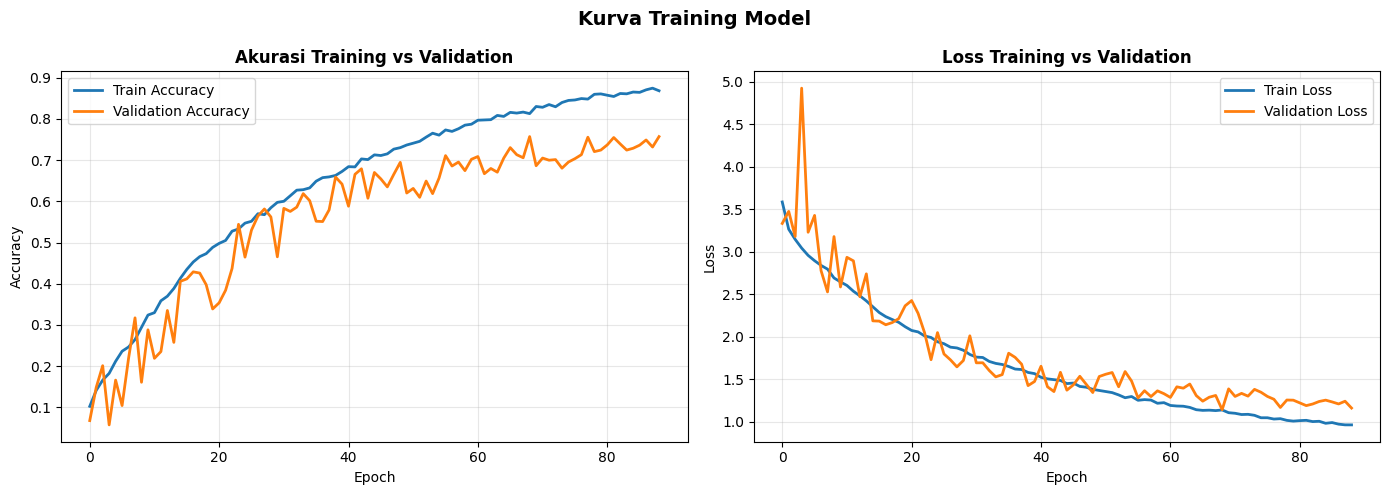


ANALISIS TRAINING (model tunggal)
Train Accuracy (tanpa aug): 0.9340
Validation Accuracy       : 0.7573
Gap                       : 0.1768
Diagnosa                  : OVERFITTING (gap 10-20 poin)
   Catatan: val dipakai untuk memilih checkpoint, jadi gap sebenarnya sedikit lebih besar. Konfirmasi dengan gap train-test di Section 7c.


In [ ]:
def plot_training_history(history):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(history.history['accuracy'], label='Train Accuracy', linewidth=2)
    axes[0].plot(history.history['val_accuracy'], label='Validation Accuracy', linewidth=2)
    axes[0].set_title('Akurasi Training vs Validation', fontweight='bold')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].plot(history.history['loss'], label='Train Loss', linewidth=2)
    axes[1].plot(history.history['val_loss'], label='Validation Loss', linewidth=2)
    axes[1].set_title('Loss Training vs Validation', fontweight='bold')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.suptitle('Kurva Training Model', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

plot_training_history(history)

train_model.load_weights(CKPT)
_, final_train_acc = train_model.evaluate(create_dataset(X_train_paths, y_train), verbose=0)
_, final_val_acc   = train_model.evaluate(val_ds, verbose=0)
gap, verdict = diagnosa(final_train_acc, final_val_acc)

print("\n" + "=" * 60)
print("ANALISIS TRAINING (model tunggal)")
print("=" * 60)
print(f"Train Accuracy (tanpa aug): {final_train_acc:.4f}")
print(f"Validation Accuracy       : {final_val_acc:.4f}")
print(f"Gap                       : {gap:.4f}")
print(f"Diagnosa                  : {verdict}")
if gap > GAP_OVERFIT:
    print("   Catatan: val dipakai untuk memilih checkpoint, jadi gap sebenarnya sedikit lebih besar. "
          "Konfirmasi dengan gap train-test di Section 7c.")

### Export model (float32, tanpa augmentasi)

Bobot terbaik dimuat ke model float32 murni, diverifikasi terhadap model training, lalu disimpan sebagai `best_fish_cnn.keras`.

In [ ]:
train_model.load_weights(CKPT)
keras.mixed_precision.set_global_policy('float32')
final_model = build_custom_cnn(INPUT_SHAPE, NUM_CLASSES, **ARCH)
final_model.set_weights(model.get_weights())

# sanity check: selisih output float32 vs model training harus kecil
xb, _ = next(iter(val_ds))
diff = np.max(np.abs(final_model.predict(xb, verbose=0) - model.predict(xb, verbose=0)))
print(f"Selisih maksimum prediksi (harus kecil, <~1e-2): {diff:.5f}")

final_model.save('best_fish_cnn.keras')
print("✅ Tersimpan: best_fish_cnn.keras")
try:
    final_model.save(f'{SAVE_DIR}/best_fish_cnn.keras')
    print("✅ Backup ke Google Drive")
except Exception as e:
    print("Backup Drive dilewati:", e)

print(f"Best val_accuracy: {max(history.history['val_accuracy']):.4f}")

Selisih maksimum prediksi (harus kecil, <~1e-2): 0.00176
✅ Tersimpan: best_fish_cnn.keras
✅ Backup ke Google Drive
Best val_accuracy: 0.7573


## 7. Evaluasi pada Test Set

Validation set sudah dipakai untuk memilih checkpoint, jadi **angka test inilah yang dilaporkan**.

### 7.1 Akurasi, macro-F1, dan classification report

In [ ]:
best_model = keras.models.load_model('best_fish_cnn.keras', compile=False)
best_model.compile(loss='sparse_categorical_crossentropy', metrics=['accuracy'])

test_loss, test_acc = best_model.evaluate(test_ds, verbose=1)
y_pred = np.argmax(best_model.predict(test_ds, verbose=0), axis=1)

print("\n" + "=" * 60)
print("HASIL EVALUASI TEST SET")
print("=" * 60)
print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_acc:.4f}")
print(f"Macro-F1            : {f1_score(y_test, y_pred, average='macro'):.4f}")

print("\n" + "=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)
print(classification_report(y_test, y_pred, target_names=class_names_ordered, zero_division=0))

44/44 ━━━━━━━━━━━━━━━━━━━━ 21s 390ms/step - accuracy: 0.7207 - loss: 1.0135

HASIL EVALUASI TEST SET
Test Loss     : 1.0135
Test Accuracy : 0.7207
Macro-F1            : 0.6909

CLASSIFICATION REPORT
                       precision    recall  f1-score   support

               Bangus       0.29      0.45      0.35        31
        Big Head Carp       0.71      0.59      0.64        29
   Black Spotted Barb       0.70      0.66      0.68        35
              Catfish       0.62      0.67      0.65        45
       Climbing Perch       0.39      0.76      0.52        21
 Fourfinger Threadfin       0.84      0.58      0.69        36
       Freshwater Eel       0.60      0.72      0.65        46
       Glass Perchlet       0.88      0.76      0.81        58
                 Goby       0.61      0.71      0.66        94
            Gold Fish       0.97      1.00      0.98        32
              Gourami       0.97      0.82      0.89        45
           Grass Carp       0.87      0.96  

### 7.2 Uji ketangguhan (robustness)

Akurasi test saat gambar diberi gangguan (noise, pencahayaan, kontras, blur, flip, rotasi, crop).

Asli              : 0.7207
Noise gaussian    : 0.3434
Lebih terang      : 0.6818
Lebih gelap       : 0.6429
Kontras rendah    : 0.5911
Blur              : 0.4478
Flip horizontal   : 0.7163
Rotasi acak       : 0.6883
Crop tengah 70%   : 0.6062


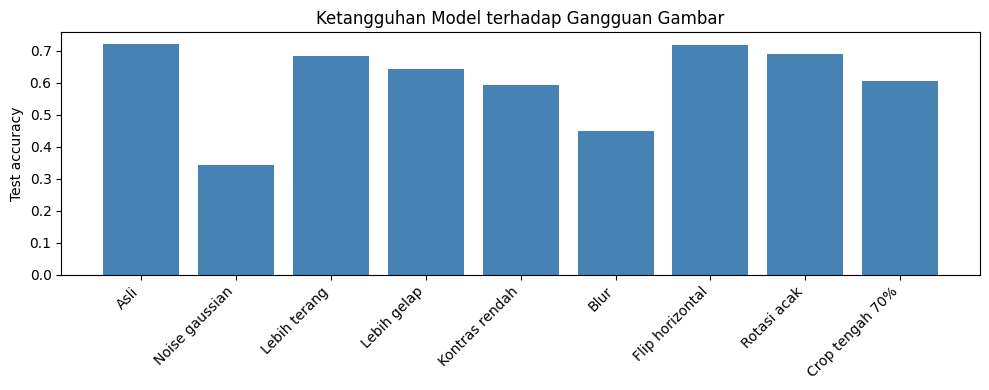

In [ ]:
rot = layers.RandomRotation(0.1, fill_mode='nearest')

def center_crop_resize(x):
    return tf.image.resize(tf.image.central_crop(x, 0.7), IMG_SIZE)

perturbasi = {
    "Asli":            lambda x: x,
    "Noise gaussian":  lambda x: x + tf.random.normal(tf.shape(x), stddev=0.1),
    "Lebih terang":    lambda x: x + 0.2,
    "Lebih gelap":     lambda x: x - 0.2,
    "Kontras rendah":  lambda x: tf.image.adjust_contrast(x, 0.5),
    "Blur":            lambda x: tf.nn.avg_pool2d(x, 5, 1, 'SAME'),
    "Flip horizontal": lambda x: tf.image.flip_left_right(x),
    "Rotasi acak":     lambda x: rot(x, training=True),
    "Crop tengah 70%": center_crop_resize,
}

robust = {}
for nama, fn in perturbasi.items():
    ds = test_ds.map(lambda x, y, fn=fn: (tf.clip_by_value(fn(x), 0.0, 1.0), y))
    _, acc = best_model.evaluate(ds, verbose=0)
    robust[nama] = acc
    print(f"{nama:<18}: {acc:.4f}")

plt.figure(figsize=(10, 4))
plt.bar(robust.keys(), robust.values(), color='steelblue')
plt.xticks(rotation=45, ha='right')
plt.ylabel('Test accuracy')
plt.title('Ketangguhan Model terhadap Gangguan Gambar')
plt.tight_layout()
plt.show()

### 7.3 Confusion matrix dan analisis error

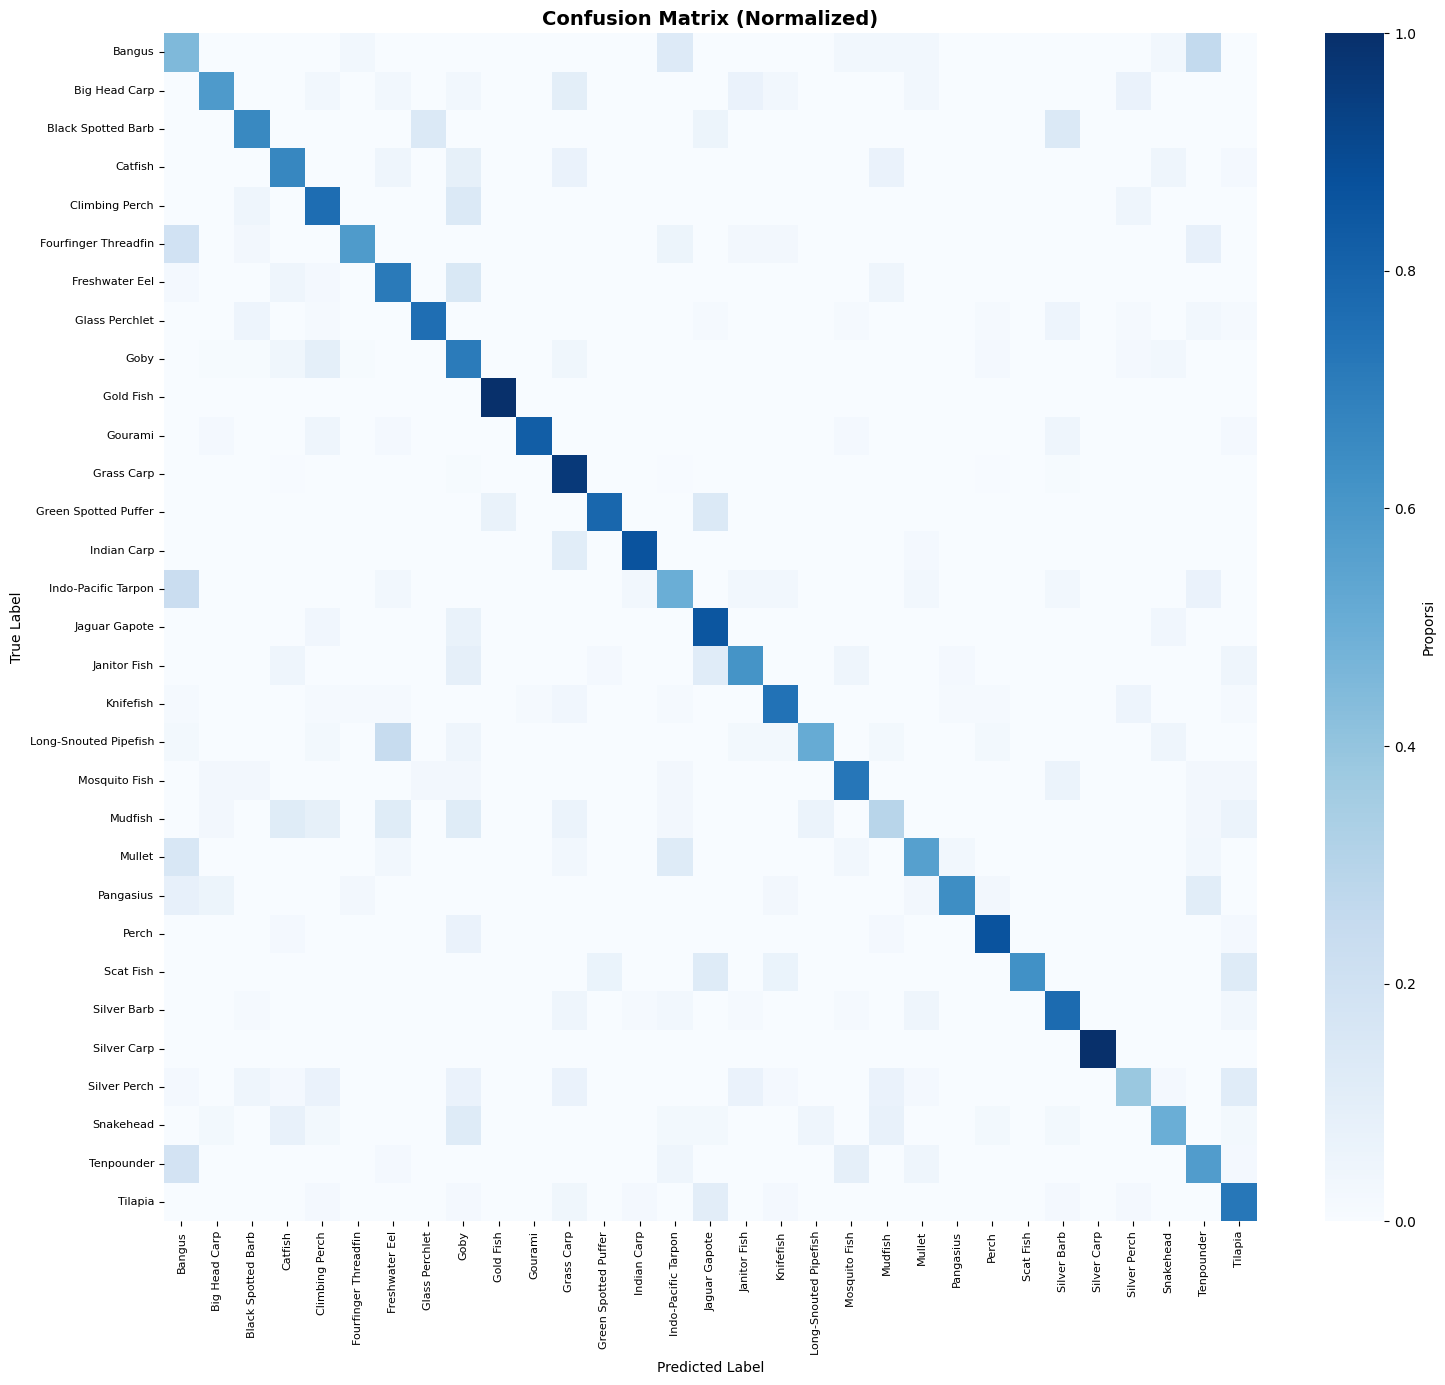

In [ ]:
cm = confusion_matrix(y_test, y_pred)
cm_norm = cm.astype('float') / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(max(10, NUM_CLASSES * 0.5), max(8, NUM_CLASSES * 0.45)))
sns.heatmap(
    cm_norm,
    annot=(NUM_CLASSES <= 15),
    fmt='.2f' if NUM_CLASSES <= 15 else '',
    cmap='Blues',
    xticklabels=class_names_ordered,
    yticklabels=class_names_ordered,
    cbar_kws={'label': 'Proporsi'},
    ax=ax
)
ax.set_title('Confusion Matrix (Normalized)', fontsize=14, fontweight='bold')
ax.set_xlabel('Predicted Label')
ax.set_ylabel('True Label')
plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.show()

In [ ]:
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)

pasangan = [(cm_off[i, j], class_names_ordered[i], class_names_ordered[j])
            for i in range(NUM_CLASSES) for j in range(NUM_CLASSES)
            if cm_off[i, j] > 0]

print("10 pasangan kelas yang paling sering tertukar (aktual -> prediksi)")
for n, aktual, prediksi in sorted(pasangan, reverse=True)[:10]:
    print(f"  {aktual:<22} -> {prediksi:<22}: {n} gambar")

10 pasangan kelas yang paling sering tertukar (aktual -> prediksi)
  Long-Snouted Pipefish  -> Freshwater Eel        : 10 gambar
  Goby                   -> Climbing Perch        : 9 gambar
  Tenpounder             -> Bangus                : 8 gambar
  Bangus                 -> Tenpounder            : 8 gambar
  Indo-Pacific Tarpon    -> Bangus                : 7 gambar
  Freshwater Eel         -> Goby                  : 7 gambar
  Fourfinger Threadfin   -> Bangus                : 7 gambar
  Tilapia                -> Jaguar Gapote         : 5 gambar
  Snakehead              -> Goby                  : 5 gambar
  Silver Perch           -> Tilapia               : 5 gambar


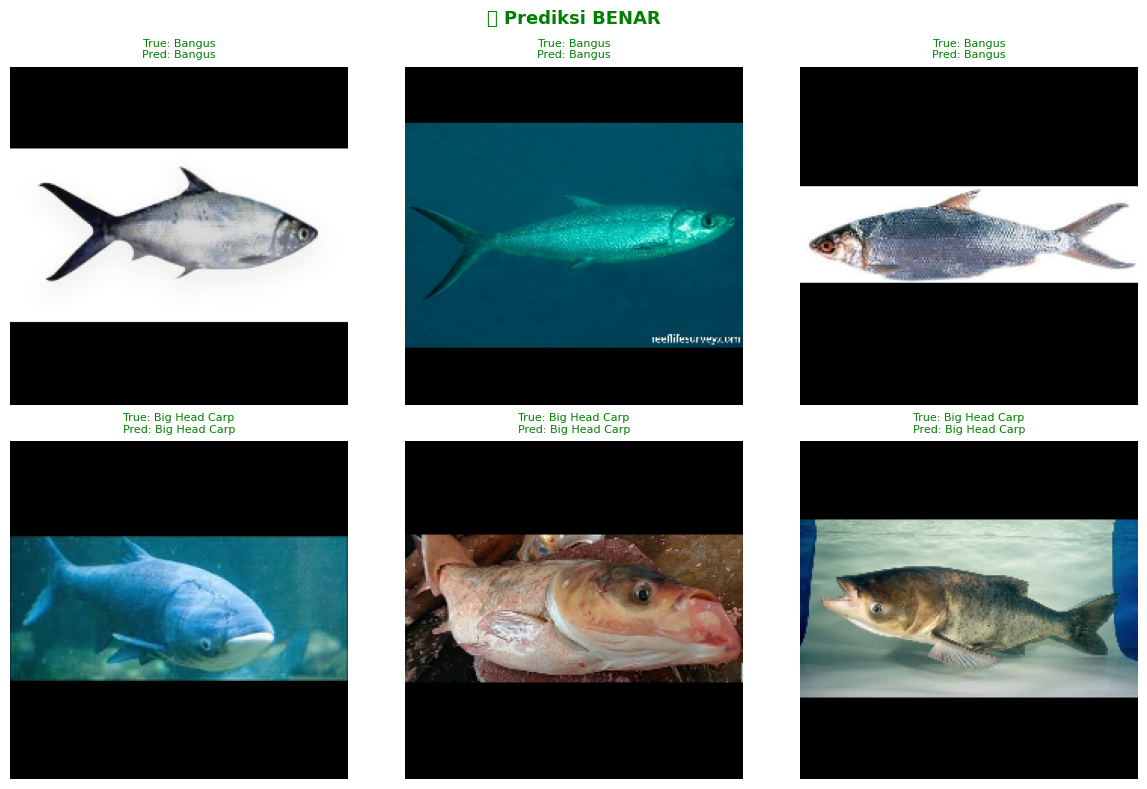

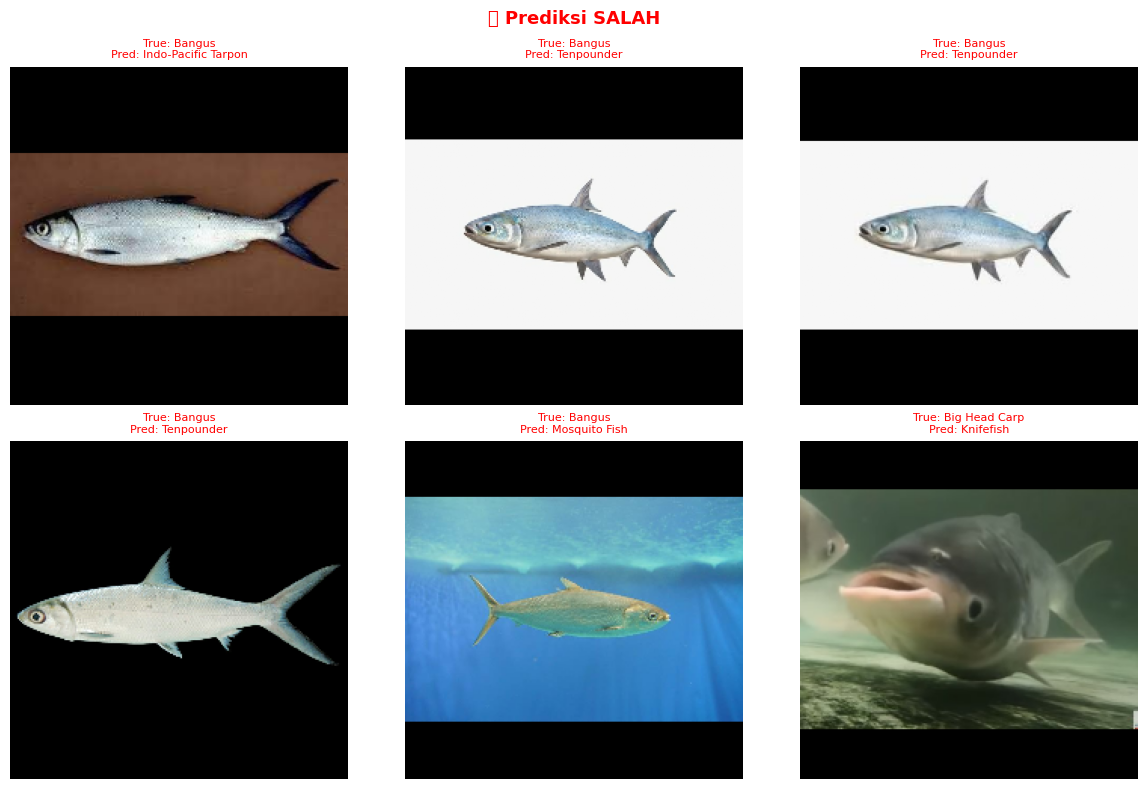

In [ ]:
def show_predictions(model, dataset, class_names, n_correct=6, n_wrong=6):
    """Menampilkan sample prediksi benar dan salah."""
    all_images, all_true, all_pred = [], [], []

    for images, labels in dataset:
        preds = model.predict(images, verbose=0)
        all_images.extend(images.numpy())
        all_true.extend(labels.numpy())
        all_pred.extend(np.argmax(preds, axis=1))
        if len(all_images) >= 200:
            break

    all_images = np.array(all_images)
    all_true = np.array(all_true)
    all_pred = np.array(all_pred)

    correct_idx = np.where(all_true == all_pred)[0]
    wrong_idx = np.where(all_true != all_pred)[0]

    sel_correct = correct_idx[:n_correct] if len(correct_idx) >= n_correct else correct_idx
    sel_wrong = wrong_idx[:n_wrong] if len(wrong_idx) >= n_wrong else wrong_idx

    if len(sel_correct) > 0:
        n_cols = min(3, len(sel_correct))
        n_rows = (len(sel_correct) + n_cols - 1) // n_cols
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(4*n_cols, 4*n_rows))
        axes = axes.flatten() if n_rows*n_cols > 1 else [axes]
        for i, idx in enumerate(sel_correct):
            axes[i].imshow(all_images[idx])
            axes[i].set_title(f"True: {class_names[all_true[idx]]}\nPred: {class_names[all_pred[idx]]}",
                              fontsize=8, color='green')
            axes[i].axis('off')
        for j in range(len(sel_correct), len(axes)):
            axes[j].axis('off')
        plt.suptitle('✅ Prediksi BENAR', fontsize=13, fontweight='bold', color='green')
        plt.tight_layout()
        plt.show()

    if len(sel_wrong) > 0:
        n_cols = min(3, len(sel_wrong))
        n_rows = (len(sel_wrong) + n_cols - 1) // n_cols
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(4*n_cols, 4*n_rows))
        axes = axes.flatten() if n_rows*n_cols > 1 else [axes]
        for i, idx in enumerate(sel_wrong):
            axes[i].imshow(all_images[idx])
            axes[i].set_title(f"True: {class_names[all_true[idx]]}\nPred: {class_names[all_pred[idx]]}",
                              fontsize=8, color='red')
            axes[i].axis('off')
        for j in range(len(sel_wrong), len(axes)):
            axes[j].axis('off')
        plt.suptitle('❌ Prediksi SALAH', fontsize=13, fontweight='bold', color='red')
        plt.tight_layout()
        plt.show()
    else:
        print("🎉 Tidak ada prediksi salah pada sampel yang diambil!")

show_predictions(best_model, test_ds, class_names_ordered)

### 7.4 Ringkasan train / val / test

Membandingkan akurasi ketiga split untuk diagnosa overfitting yang final.

In [ ]:
acc = {}
for nama, ds, y in [('train', create_dataset(X_train_paths, y_train), y_train),
                    ('val', val_ds, y_val),
                    ('test', test_ds, y_test)]:
    pred = np.argmax(best_model.predict(ds, verbose=0), axis=1)
    acc[nama] = float((pred == y).mean())

gap_val, verdict_val = diagnosa(acc['train'], acc['val'])
gap_test, verdict_test = diagnosa(acc['train'], acc['test'])

print("=" * 60)
print("RINGKASAN AKURASI (train tanpa augmentasi)")
print("=" * 60)
print(f"Train : {acc['train']:.4f}")
print(f"Val   : {acc['val']:.4f}   gap train-val : {gap_val:+.4f}  -> {verdict_val}")
print(f"Test  : {acc['test']:.4f}   gap train-test: {gap_test:+.4f}  -> {verdict_test}")

n, p = len(y_test), acc['test']
print(f"\nGalat baku akurasi test (95%): ±{100 * 1.96 * np.sqrt(p * (1 - p) / n):.1f} poin")

RINGKASAN AKURASI (train tanpa augmentasi)
Train : 0.9342
Val   : 0.7565   gap train-val : +0.1777  -> OVERFITTING (gap 10-20 poin)
Test  : 0.7207   gap train-test: +0.2135  -> OVERFITTING BERAT (gap > 20 poin)

Galat baku akurasi test (95%): ±2.4 poin


## 8. Simpan Model & Label Mapping

Artefak deployment dikumpulkan di `deploy_artifacts/` lalu di-zip: model `.keras`, `class_indices.json`, dan `preprocess_config.json`.

In [ ]:
DEPLOY_DIR = 'deploy_artifacts'
shutil.rmtree(DEPLOY_DIR, ignore_errors=True)
os.makedirs(DEPLOY_DIR)

shutil.copy('best_fish_cnn.keras', os.path.join(DEPLOY_DIR, 'fish_cnn_model.keras'))

with open(os.path.join(DEPLOY_DIR, 'class_indices.json'), 'w') as f:
    json.dump(class_to_idx, f, indent=2)

PREPROCESS_CONFIG = {
    'image_size': list(IMG_SIZE),
    'rescale_factor': 1.0 / 255.0,
    'resize_mode': 'pad' if USE_PAD else 'stretch',
    'num_classes': NUM_CLASSES,
    'class_names': class_names_ordered
}
with open(os.path.join(DEPLOY_DIR, 'preprocess_config.json'), 'w') as f:
    json.dump(PREPROCESS_CONFIG, f, indent=2)

try:
    shutil.copytree(DEPLOY_DIR, f'{SAVE_DIR}/deploy_artifacts', dirs_exist_ok=True)
    print("✅ Backup ke Google Drive")
except Exception as e:
    print("Backup Drive dilewati:", e)

print(f"\nIsi {DEPLOY_DIR}/")
for fn in sorted(os.listdir(DEPLOY_DIR)):
    print(f"  {fn:<28} {os.path.getsize(os.path.join(DEPLOY_DIR, fn)) / 1e6:>6.2f} MB")

✅ Backup ke Google Drive

Isi deploy_artifacts/
  class_indices.json             0.00 MB
  fish_cnn_model.keras          11.86 MB
  preprocess_config.json         0.00 MB


In [ ]:
zip_path = shutil.make_archive('deploy_artifacts', 'zip', DEPLOY_DIR)
try:
    from google.colab import files
    print("Mengunduh", zip_path, "...")
    files.download(zip_path)
    print("✅ Ekstrak zip, lalu letakkan SEMUA isinya di folder yang sama dengan app.py.")
except ImportError:
    print("Bukan Colab. Zip tersimpan di:", os.path.abspath(zip_path))

Mengunduh /content/deploy_artifacts.zip ...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Ekstrak zip, lalu letakkan SEMUA isinya di folder yang sama dengan app.py.


## 9. Deployment dengan Streamlit

Letakkan seluruh isi `deploy_artifacts.zip` di folder yang sama dengan `app.py`, lalu jalankan:

```bash
pip install -r requirements.txt
streamlit run app.py
```

Preprocessing di `app.py` harus **persis sama** dengan training (resize dengan padding, lalu bagi 255):

```python
import json
import numpy as np
import tensorflow as tf
from tensorflow import keras
import streamlit as st

@st.cache_resource
def load_model():
    model = keras.models.load_model('fish_cnn_model.keras', compile=False)
    class_names = json.load(open('preprocess_config.json'))['class_names']
    return model, class_names

def predict(img):
    model, class_names = load_model()
    x = tf.image.resize_with_pad(np.array(img.convert('RGB')), 224, 224)
    x = tf.cast(tf.round(x), tf.uint8)
    x = tf.cast(x, tf.float32) / 255.0
    probs = model.predict(x[None], verbose=0)[0]
    return class_names, probs
```

## 10. Eksplorasi Hyperparameter (opsional, belum dijalankan)

Section ini **belum pernah dijalankan sampai selesai** sehingga belum ada hasilnya, dan tidak memengaruhi model di atas. Tiap eksperimen mengubah satu hal dari konfigurasi utama dan dibandingkan lewat `val_macroF1` (20 epoch per eksperimen, ±10 menit).

Catatan membaca hasil: tiap eksperimen hanya satu kali jalan dengan satu seed, jadi selisih kecil (di bawah ±2–3 poin) belum bisa dianggap perbaikan nyata.

In [ ]:
EXP_EPOCHS = 20
results = []

def run_experiment(name, epochs=EXP_EPOCHS, peak_lr=PEAK_LR, wd=WEIGHT_DECAY, ls=LABEL_SMOOTH, **arch_over):
    keras.backend.clear_session()
    if USE_MIXED_PRECISION and tf.config.list_physical_devices('GPU'):
        keras.mixed_precision.set_global_policy('mixed_float16')
    arch = {**ARCH, **arch_over}
    net = build_custom_cnn(INPUT_SHAPE, NUM_CLASSES, **arch)
    tm = make_trainable(net, epochs, peak_lr, wd, ls)
    h = tm.fit(train_ds, validation_data=val_ds, epochs=epochs, verbose=0,
               callbacks=[callbacks.EarlyStopping(monitor='val_accuracy', mode='max',
                                                  patience=10, restore_best_weights=True)])
    pred = np.argmax(net.predict(val_ds, verbose=0), axis=1)
    results.append({
        "eksperimen": name, "peak_lr": peak_lr, "weight_decay": wd, "label_smooth": ls,
        "base": arch["base"], "SE": arch["use_se"],
        "head_drop": arch["head_drop"], "stage_drop": arch["stage_drop"],
        "params": net.count_params(),
        "train_acc_aug": round(max(h.history['accuracy']), 4),
        "val_acc": round(max(h.history['val_accuracy']), 4),
        "val_macroF1": round(f1_score(y_val, pred, average='macro'), 4),
    })
    print(results[-1])
    pd.DataFrame(results).to_csv(f'{SAVE_DIR}/hyperparam_results.csv', index=False)

EKSPERIMEN = [
    ("baseline_mixup_cutmix", {}),
    ("wd_0.02",              dict(wd=0.02)),
    ("tanpa_stage_dropout",  dict(stage_drop=0.0)),
    ("base48_lebih_besar",   dict(base=48)),
    ("tanpa_SE",             dict(use_se=False)),
]

try:
    for nama, kw in EKSPERIMEN:
        run_experiment(nama, **kw)
except KeyboardInterrupt:
    print("\nDihentikan manual. Menampilkan hasil yang sudah selesai.")

if results:
    display(pd.DataFrame(results).sort_values("val_macroF1", ascending=False))
else:
    print("Belum ada eksperimen yang selesai.")

{'eksperimen': 'baseline_mixup_cutmix', 'peak_lr': 0.001, 'weight_decay': 0.01, 'label_smooth': 0.05, 'base': 32, 'SE': True, 'head_drop': 0.5, 'stage_drop': 0.1, 'params': 2863423, 'train_acc_aug': 0.5064, 'val_acc': 0.5696, 'val_macroF1': 0.5022}
{'eksperimen': 'wd_0.02', 'peak_lr': 0.001, 'weight_decay': 0.02, 'label_smooth': 0.05, 'base': 32, 'SE': True, 'head_drop': 0.5, 'stage_drop': 0.1, 'params': 2863423, 'train_acc_aug': 0.487, 'val_acc': 0.5391, 'val_macroF1': 0.4563}
{'eksperimen': 'tanpa_stage_dropout', 'peak_lr': 0.001, 'weight_decay': 0.01, 'label_smooth': 0.05, 'base': 32, 'SE': True, 'head_drop': 0.5, 'stage_drop': 0.0, 'params': 2863423, 'train_acc_aug': 0.5656, 'val_acc': 0.5897, 'val_macroF1': 0.512}
{'eksperimen': 'base48_lebih_besar', 'peak_lr': 0.001, 'weight_decay': 0.01, 'label_smooth': 0.05, 'base': 48, 'SE': True, 'head_drop': 0.5, 'stage_drop': 0.1, 'params': 6427079, 'train_acc_aug': 0.5568, 'val_acc': 0.5704, 'val_macroF1': 0.4944}
{'eksperimen': 'tanpa_SE'

,eksperimen,peak_lr,weight_decay,label_smooth,base,SE,head_drop,stage_drop,params,train_acc_aug,val_acc,val_macroF1
2,tanpa_stage_dropout,0.001,0.01,0.05,32,True,0.5,0.0,2863423,0.5656,0.5897,0.5120
0,baseline_mixup_cutmix,0.001,0.01,0.05,32,True,0.5,0.1,2863423,0.5064,0.5696,0.5022
3,base48_lebih_besar,0.001,0.01,0.05,48,True,0.5,0.1,6427079,0.5568,0.5704,0.4944
1,wd_0.02,0.001,0.02,0.05,32,True,0.5,0.1,2863423,0.4870,0.5391,0.4563
4,tanpa_SE,0.001,0.01,0.05,32,False,0.5,0.1,2818303,0.4173,0.4371,0.3558
